# NexaTel Customer Churn: Phase 2 Exploratory Data Analysis (EDA)

**What this notebook does:** it uses the cleaned tables from Phase 1 (`*_clean.csv`) to build 10 charts that show who churns and what goes with churn. Every chart is saved as a PNG in the `NexaTel/charts` folder and has a short observation under it.

## Assumptions and notes
- **Churn rate** in this notebook is the all-time share of customers whose status is Churned. It is not a monthly rate (monthly churn is calculated in Phase 3).
- **Tenure bands:** 0-3 months, 3-12 months, 1-3 years (12-35 months) and 3+ years (36+ months). The lower edge of each band is included.
- **Billing cycle** comes from each customer's plan (`customers.plan_id` linked to `plans.csv`). That gives one plan per customer, so customers who hold two subscriptions are not counted twice.
- **Data usage** (chart 7) uses the cleaned usage file, so the 171 extreme values blanked in Phase 1 are excluded.
- **Monthly charge** (chart 8) covers active subscriptions only. Subscriptions above Rs.3,000 are left off the chart to keep it readable, but they are included in the mean and median.
- **Dropped-call rate** (chart 9) is each customer's average over Jan-Mar 2026, with customers split into four equal-sized groups.
- **Retained** (chart 10) means the customer is still Active. There is no comparison group of customers who were not contacted.
- Every chart shows an association between two things. None of them proves that one causes the other.

## Setup: connect Drive and load the cleaned customers table

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/NexaTel/"
DATA = BASE + "data/"
CHARTS = BASE + "charts/"
os.makedirs(CHARTS, exist_ok=True)

customers = pd.read_csv(DATA + "customers_clean.csv",
                        parse_dates=["date_of_birth", "acquisition_date", "churn_date"])
print(customers.shape)

Mounted at /content/drive
(19000, 25)


## Chart 1: Overall churn rate

customer_status
Active     15494
Churned     3506
Name: count, dtype: int64
Churn rate: 18.5%


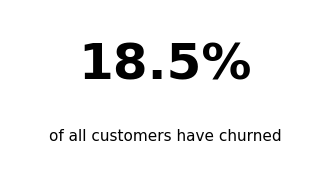

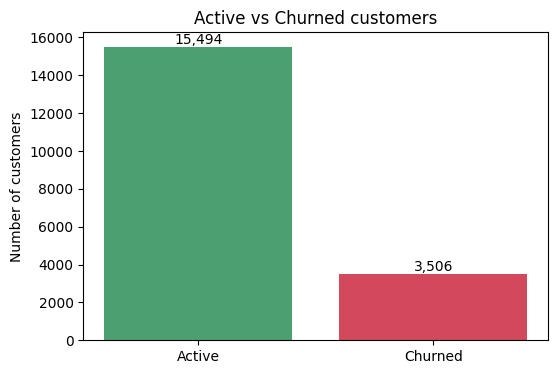

In [2]:
# How many customers are Active vs Churned?
counts = customers["customer_status"].value_counts().reindex(["Active", "Churned"])
print(counts)

# Churn rate = share of customers whose status is Churned
churn_rate = (customers["customer_status"] == "Churned").mean() * 100
print(f"Churn rate: {churn_rate:.1f}%")

# KPI card: one big number
fig, ax = plt.subplots(figsize=(4, 2))
ax.axis("off")
ax.text(0.5, 0.55, f"{churn_rate:.1f}%", ha="center", fontsize=36, weight="bold")
ax.text(0.5, 0.15, "of all customers have churned", ha="center", fontsize=11)
plt.savefig(CHARTS + "chart01a_churn_kpi.png", dpi=150, bbox_inches="tight")
plt.show()

# Bar chart: Active vs Churned
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=["#4C9F70", "#D1495B"])
plt.title("Active vs Churned customers")
plt.ylabel("Number of customers")
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.savefig(CHARTS + "chart01b_active_vs_churned.png", dpi=150, bbox_inches="tight")
plt.show()

Of 19,000 customers, 3,506 (18.5%) have churned and 15,494 are still active. This is churn over the whole customer history, not a monthly rate, so it can’t be compared directly with the monthly churn target.

## Helper: churned flag and a reusable bar-chart function

In [3]:
customers["churned"] = customers["customer_status"] == "Churned"

def churn_bar(rates, title, xlabel, filename):
    plt.figure(figsize=(7, 4))
    plt.bar(rates.index.astype(str), rates.values, color="#D1495B")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Churn rate (%)")
    for i, v in enumerate(rates.values):
        plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
    plt.savefig(CHARTS + filename, dpi=150, bbox_inches="tight")
    plt.show()

## Chart 2: Churn by billing cycle

               churn_rate_%  customers
billing_cycle                         
Annual                  7.2       5051
Monthly                22.5      13949


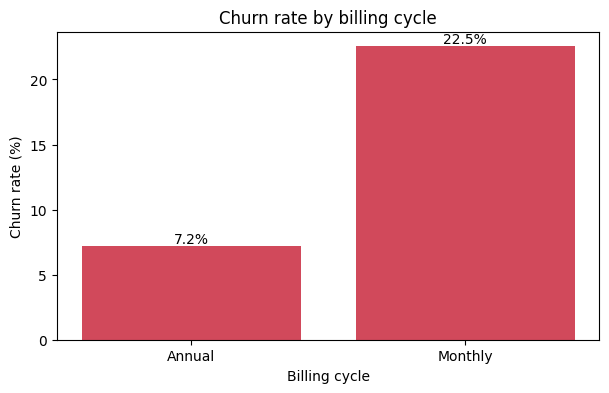

In [4]:
plans = pd.read_csv(DATA + "plans.csv")
customers["billing_cycle"] = customers["plan_id"].map(plans.set_index("plan_id")["billing_cycle"])

rate = customers.groupby("billing_cycle")["churned"].mean() * 100
size = customers.groupby("billing_cycle").size()
print(pd.DataFrame({"churn_rate_%": rate.round(1), "customers": size}))

churn_bar(rate, "Churn rate by billing cycle", "Billing cycle", "chart02_churn_by_billing_cycle.png")

Monthly-plan customers churn at 22.5%, about three times the Annual-plan rate of 7.2%. Annual customers may be tied in for longer, but this chart alone doesn’t show why.

## Chart 3: Churn by tenure band

             churn_rate_%  customers
tenure_band                         
0-3 months           78.8        562
3-12 months          54.4       1479
1-3 years            36.9       2898
3+ years              8.5      14061


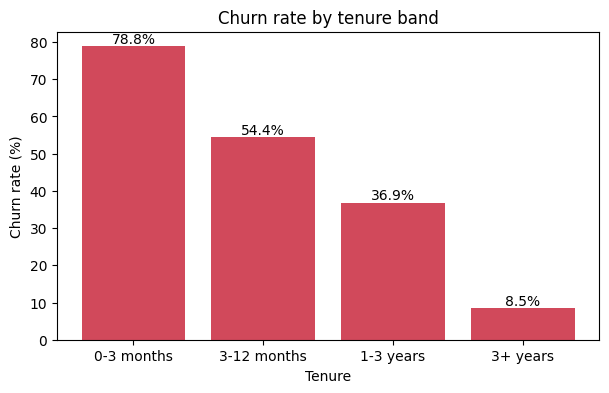

In [5]:
bins = [0, 3, 12, 36, 1000]
labels = ["0-3 months", "3-12 months", "1-3 years", "3+ years"]
customers["tenure_band"] = pd.cut(customers["tenure_months"], bins=bins, labels=labels, right=False)

rate = customers.groupby("tenure_band", observed=True)["churned"].mean() * 100
size = customers.groupby("tenure_band", observed=True).size()
print(pd.DataFrame({"churn_rate_%": rate.round(1), "customers": size}))

churn_bar(rate, "Churn rate by tenure band", "Tenure", "chart03_churn_by_tenure.png")

Churn falls sharply with tenure, from 78.8% for customers under 3 months to 8.5% for those with 3+ years. Most customers (14,061) are in the 3+ year band. Tenure for churned customers stops at their exit date, so part of this pattern comes from how tenure is measured.

## Chart 4: Churn by number of unresolved complaints

                  churn_rate_%  customers
unresolved_group                         
0                         15.1      12942
1                         23.4       4934
2                         33.3        975
3+                        48.3        149


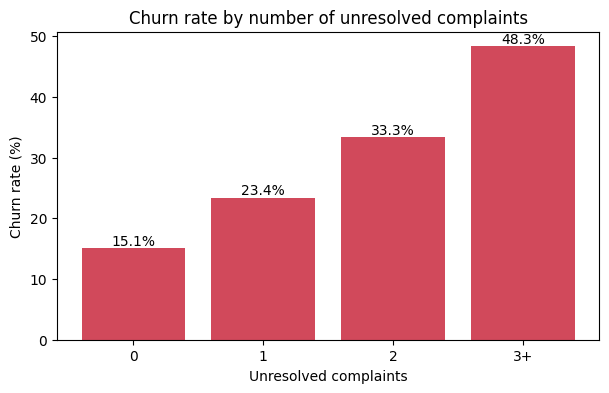

In [6]:
complaints = pd.read_csv(DATA + "complaints.csv")
unresolved = complaints[complaints["status"] == "Unresolved"]
n_unres = unresolved.groupby("customer_id").size()

customers["unresolved_complaints"] = customers["customer_id"].map(n_unres).fillna(0).astype(int)
customers["unresolved_group"] = customers["unresolved_complaints"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})

order = ["0", "1", "2", "3+"]
rate = (customers.groupby("unresolved_group")["churned"].mean() * 100).reindex(order)
size = customers.groupby("unresolved_group").size().reindex(order)
print(pd.DataFrame({"churn_rate_%": rate.round(1), "customers": size}))

churn_bar(rate, "Churn rate by number of unresolved complaints", "Unresolved complaints", "chart04_churn_by_unresolved.png")

Churn rises with each extra unresolved complaint: 15.1% with none, 23.4% with one, 33.3% with two and 48.3% with three or more. The 3+ group is small (149 customers). This shows an association, not proof that complaints cause churn, and about a quarter of the unresolved complaints from churned customers are dated after they left.

## Chart 5: Churn by customer segment

                  churn_rate_%  customers
customer_segment                         
Mass                      26.7       2932
Value                     20.6       6196
Premium                   15.1       8482
Enterprise                11.9       1390


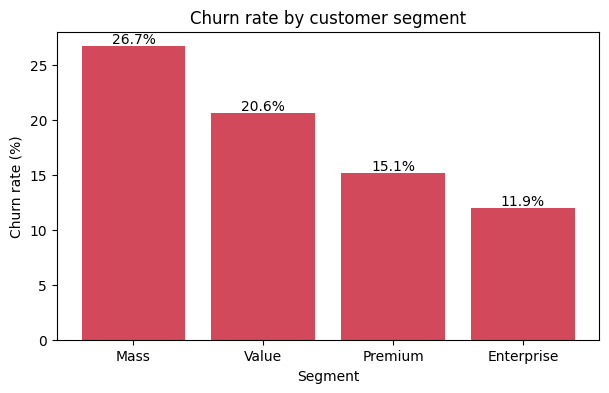

In [7]:
order = ["Mass", "Value", "Premium", "Enterprise"]
rate = (customers.groupby("customer_segment")["churned"].mean() * 100).reindex(order)
size = customers.groupby("customer_segment").size().reindex(order)
print(pd.DataFrame({"churn_rate_%": rate.round(1), "customers": size}))

churn_bar(rate, "Churn rate by customer segment", "Segment", "chart05_churn_by_segment.png")

Churn falls as the segment goes up: Mass 26.7%, Value 20.6%, Premium 15.1% and Enterprise 11.9%. Mass customers churn at more than twice the Enterprise rate. Premium is the largest segment (8,482 customers), so its low churn helps keep the overall rate down.

## Chart 6: Top 10 states by churned customers

                churned_customers  customers  churn_rate_%
state_name                                                
Maharashtra                   305       1876          16.3
Uttar Pradesh                 285       1657          17.2
Tamil Nadu                    280       1501          18.7
Rajasthan                     244       1336          18.3
Karnataka                     222       1164          19.1
Gujarat                       191       1130          16.9
Madhya Pradesh                182        981          18.6
Kerala                        162        861          18.8
Andhra Pradesh                160        832          19.2
West Bengal                   157        817          19.2


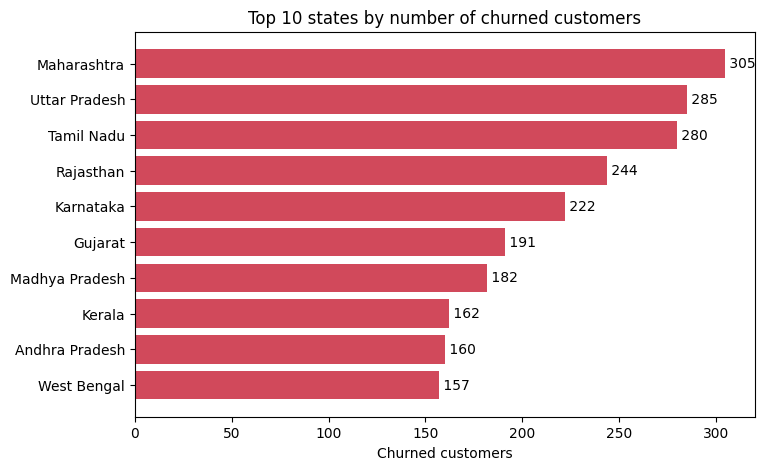

In [8]:
states = pd.read_csv(DATA + "states.csv")
customers["state_name"] = customers["state_id"].map(states.set_index("state_id")["state_name"])

by_state = customers.groupby("state_name").agg(churned_customers=("churned", "sum"),
                                              customers=("churned", "size"))
by_state["churn_rate_%"] = (by_state["churned_customers"] / by_state["customers"] * 100).round(1)
top10 = by_state.sort_values("churned_customers", ascending=False).head(10)
print(top10)

plt.figure(figsize=(8, 5))
plt.barh(top10.index, top10["churned_customers"], color="#D1495B")
plt.gca().invert_yaxis()
plt.title("Top 10 states by number of churned customers")
plt.xlabel("Churned customers")
for i, v in enumerate(top10["churned_customers"]):
    plt.text(v, i, f" {v:,}", va="center")
plt.savefig(CHARTS + "chart06_top10_states_churned.png", dpi=150, bbox_inches="tight")
plt.show()

Maharashtra (305), Uttar Pradesh (285) and Tamil Nadu (280) have the most churned customers. These are large states, and the churn rates of the top 10 states (16.3% to 19.2%) are all close to the overall 18.5%. So the ranking mostly reflects state size, not unusually high churn.

## Chart 7: Average data usage by city tier

           mean  median  count
city_tier                     
Metro      36.0    26.4  14536
Tier-2     26.5    19.4  27547
Tier-3     18.4    13.4  14746


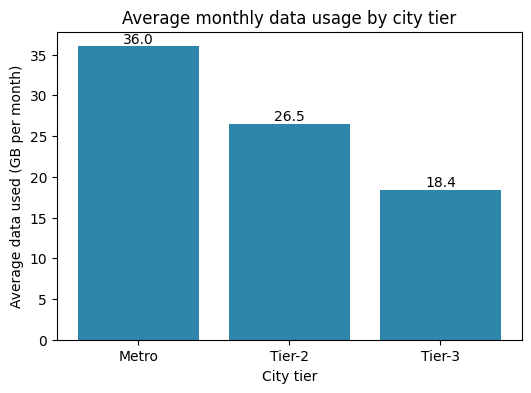

In [9]:
usage = pd.read_csv(DATA + "usage_data_clean.csv")
usage = usage.merge(customers[["customer_id", "city_tier"]], on="customer_id", how="left")

tier_order = ["Metro", "Tier-2", "Tier-3"]
avg = usage.groupby("city_tier")["data_gb_used"].agg(["mean", "median", "count"]).reindex(tier_order).round(1)
print(avg)

plt.figure(figsize=(6, 4))
plt.bar(avg.index, avg["mean"], color="#2E86AB")
plt.title("Average monthly data usage by city tier")
plt.xlabel("City tier")
plt.ylabel("Average data used (GB per month)")
for i, v in enumerate(avg["mean"]):
    plt.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.savefig(CHARTS + "chart07_data_usage_by_tier.png", dpi=150, bbox_inches="tight")
plt.show()

Metro customers use the most data (36.0 GB a month on average), then Tier-2 (26.5 GB) and Tier-3 (18.4 GB). Averages are higher than medians (26.4, 19.4 and 13.4 GB) because a minority of heavy users pull them up. The 171 extreme values removed in Phase 1 are excluded.

## Chart 8: Monthly charge (ARPU) distribution

Active subscriptions: 17017 | mean: 883 | median: 499 | above 3000: 888


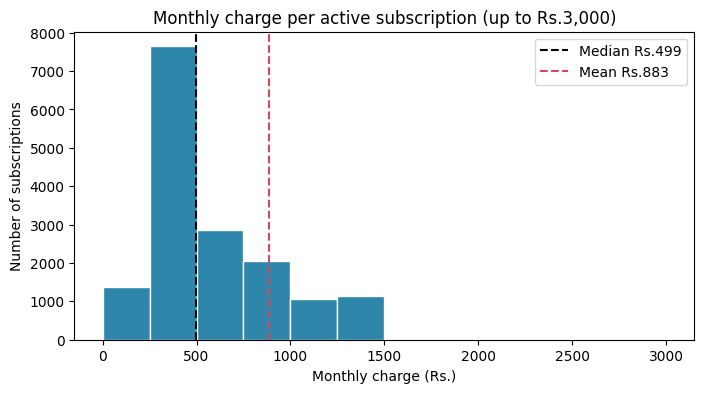

In [10]:
subs = pd.read_csv(DATA + "subscriptions_clean.csv")
active = subs[subs["subscription_status"] == "Active"]
charge = active["monthly_charge_inr"]

print("Active subscriptions:", len(charge), "| mean:", round(charge.mean()), "| median:", round(charge.median()),
      "| above 3000:", (charge > 3000).sum())

plt.figure(figsize=(8, 4))
plt.hist(charge[charge <= 3000], bins=range(0, 3250, 250), color="#2E86AB", edgecolor="white")
plt.axvline(charge.median(), color="black", linestyle="--", label=f"Median Rs.{charge.median():,.0f}")
plt.axvline(charge.mean(), color="#D1495B", linestyle="--", label=f"Mean Rs.{charge.mean():,.0f}")
plt.title("Monthly charge per active subscription (up to Rs.3,000)")
plt.xlabel("Monthly charge (Rs.)")
plt.ylabel("Number of subscriptions")
plt.legend()
plt.savefig(CHARTS + "chart08_arpu_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Active subscriptions are priced low: the median is ₹499 a month, but a smaller number of expensive plans pull the mean up to ₹883. 888 subscriptions (5.2%) charge more than ₹3,000 and are not shown. Because prices are so skewed, the median is a better picture of a typical customer than the mean.

## Chart 9: Churn vs dropped-call rate

              churn_rate_%  customers   min   max
drop_band                                        
Lowest 25%            14.9       4757  0.05  1.61
Low-mid 25%           17.2       4753  1.61  2.33
High-mid 25%          18.9       4741  2.34  3.13
Highest 25%           22.8       4749  3.14  8.25


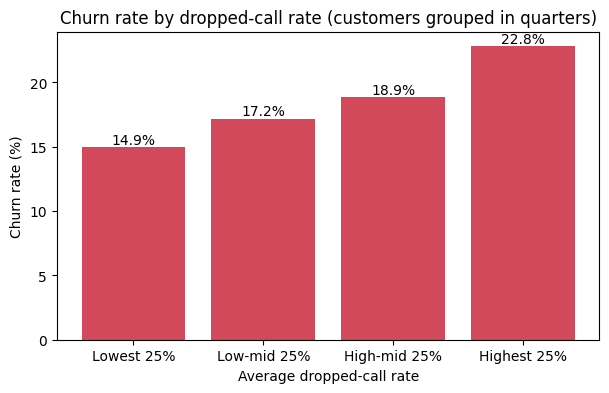

In [11]:
net = pd.read_csv(DATA + "network_quality.csv")
avg_drop = net.groupby("customer_id")["dropped_call_rate_pct"].mean()
customers["avg_dropped_call_rate"] = customers["customer_id"].map(avg_drop)

labels = ["Lowest 25%", "Low-mid 25%", "High-mid 25%", "Highest 25%"]
customers["drop_band"] = pd.qcut(customers["avg_dropped_call_rate"], 4, labels=labels)

rate = customers.groupby("drop_band", observed=True)["churned"].mean() * 100
size = customers.groupby("drop_band", observed=True).size()
ranges = customers.groupby("drop_band", observed=True)["avg_dropped_call_rate"].agg(["min", "max"]).round(2)
print(pd.DataFrame({"churn_rate_%": rate.round(1), "customers": size}).join(ranges))

churn_bar(rate, "Churn rate by dropped-call rate (customers grouped in quarters)", "Average dropped-call rate", "chart09_churn_by_dropped_calls.png")

Churn rises as the dropped-call rate rises: 14.9% in the lowest quarter, then 17.2%, 18.9% and 22.8% in the highest quarter (average rate above 3.1%). The network data only covers Jan–Mar 2026, while most churned customers (3,041 of 3,506) left before 2026, so this shows an association, not that poor network quality came first.

## Chart 10: Retention campaign outcomes

             contacted  retained_%
response                          
Accepted          2982        86.8
Declined          1877        79.2
No Response       1616        78.1
Overall retained share: 82.4 %


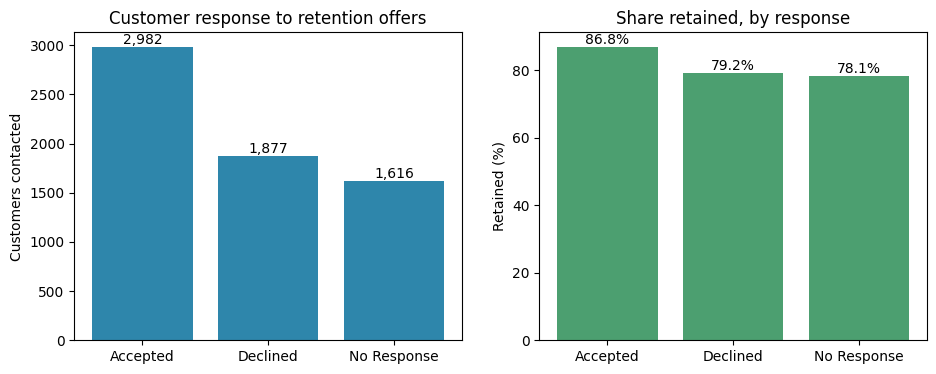

In [12]:
camp = pd.read_csv(DATA + "retention_campaigns.csv")
order = ["Accepted", "Declined", "No Response"]

counts = camp["response"].value_counts().reindex(order)
retained = (camp["retained_flag"] == "Yes").groupby(camp["response"]).mean().reindex(order) * 100
print(pd.DataFrame({"contacted": counts, "retained_%": retained.round(1)}))
print("Overall retained share:", round((camp["retained_flag"] == "Yes").mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(counts.index, counts.values, color="#2E86AB")
axes[0].set_title("Customer response to retention offers")
axes[0].set_ylabel("Customers contacted")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

axes[1].bar(retained.index, retained.values, color="#4C9F70")
axes[1].set_title("Share retained, by response")
axes[1].set_ylabel("Retained (%)")
for i, v in enumerate(retained.values):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")

plt.savefig(CHARTS + "chart10_retention_outcomes.png", dpi=150, bbox_inches="tight")
plt.show()

Of 6,475 customers contacted, 2,982 accepted the offer, 1,877 declined and 1,616 did not respond. Customers who accepted were retained at 86.8%, compared with 79.2% for decliners and 78.1% for no response (82.4% overall). “Retained” means the customer is still active, and there’s no comparison group that was not contacted, so this does not prove the campaigns caused the difference.

## Supporting checks for the notes above
These cells calculate the facts quoted in the observations, so every number can be traced back to the data.

In [13]:
# Supporting checks for the notes above
churned_df = customers[customers["churned"]]
print("Churned before 2026:", (churned_df["churn_date"] < "2026-01-01").sum(), "of", len(churned_df))

months_to_churn = (churned_df["churn_date"] - churned_df["acquisition_date"]).dt.days / 30.44
gap = (churned_df["tenure_months"] - months_to_churn).abs()
print("Churned customers whose tenure matches join-to-churn time:", round((gap <= 1.5).mean() * 100, 1), "%")

cm = complaints.copy()
cm["complaint_date"] = pd.to_datetime(cm["complaint_date"], format="%d-%m-%Y", errors="coerce")
u = cm[cm["status"] == "Unresolved"].merge(customers[["customer_id", "churned", "churn_date"]], on="customer_id")
uc = u[u["churned"]]
print("Unresolved complaints from churned customers:", len(uc), "| dated after churn_date:", round((uc["complaint_date"] > uc["churn_date"]).mean() * 100, 1), "%")

Churned before 2026: 3041 of 3506
Churned customers whose tenure matches join-to-churn time: 100.0 %
Unresolved complaints from churned customers: 2025 | dated after churn_date: 24.0 %
